In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from photutils.aperture import CircularAperture, aperture_photometry
from photutils.segmentation import SegmentationImage, SourceCatalog
from photutils.centroids import centroid_2dg

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})

with fits.open(DATA / "mosaic.fits") as hdul:
    data = hdul[0].data.astype(float); header = hdul[0].header
mask = fits.getdata(RES / "mask.fits").astype(bool)
segm = fits.getdata(RES / "segmentation.fits").astype(np.int64)
bkg = fits.getdata(RES / "background.fits").astype(float)
cat = Table.read(RES / "calibrated_catalogue.ecsv")
sdss = Table.read(DATA / "sdss_stars.csv", format="ascii.csv", comment="#")
AREA_DEG2 = float((~mask).sum()) * (float(header.get("PIXSCAL1", 0.258)) / 3600) ** 2

# Parameters (Cris's classifier/config.py)
SKY_LEVEL = 3418.5
R_SMALL, R_BIG = 2.5, 6.0
BIN, MAG_RANGE = 0.5, (19.0, 26.0)
N_SIGMA = 2.5               # within 2.5 locus widths of the locus = star
SEPARATION_SIGMA = 3.0      # classify only where galaxies are >= 3 widths above the locus
STAR_FIT_RANGE_MIN, SDSS_STAR_LIMIT, MATCH_PX = 19.5, 21.5, 2.0

In [2]:
data_sub = data - bkg
sc = SourceCatalog(data_sub, SegmentationImage(segm), mask=mask)
r50_all = sc.fluxfrac_radius(0.5); r50_all = np.asarray(getattr(r50_all, "value", r50_all), float)
lookup = dict(zip(np.asarray(sc.label), r50_all))
r50 = np.array([lookup.get(int(l), np.nan) for l in cat["label"]])
pos = np.c_[np.asarray(cat["x"]), np.asarray(cat["y"])]
clean_img = np.where(mask, 0.0, data_sub)
f_small = np.asarray(aperture_photometry(clean_img, CircularAperture(pos, R_SMALL))["aperture_sum"])
f_big = np.asarray(aperture_photometry(clean_img, CircularAperture(pos, R_BIG))["aperture_sum"])
with np.errstate(divide="ignore", invalid="ignore"):
    conc = -2.5 * np.log10(f_small / f_big)
mag = np.asarray(cat["r_point"], float); flag = np.asarray(cat["flag"])

In [3]:
def centroid(x, y, half):
    a, b = int(round(x)), int(round(y))
    cut = data[b - half:b + half + 1, a - half:a + half + 1] - SKY_LEVEL
    if cut.shape != (2 * half + 1, 2 * half + 1) or cut.max() < 100:
        return np.nan, np.nan
    cx, cy = centroid_2dg(cut)
    return cx + a - half, cy + b - half


x0, y0 = WCS(header).all_world2pix(sdss["ra"], sdss["dec"], 0)
cx_all, cy_all = np.asarray(cat["x"]), np.asarray(cat["y"])
star_idx = np.full(len(sdss), -1)
for i, (a, b) in enumerate(zip(x0, y0)):
    xa, ya = centroid(a, b, 10)
    if np.isfinite(xa):
        xa, ya = centroid(xa, ya, 6)
    if np.isfinite(xa):
        d = np.hypot(cx_all - xa, cy_all - ya); j = int(np.argmin(d))
        if d[j] < MATCH_PX:
            star_idx[i] = j
print(f"SDSS stars matched to our catalogue: {(star_idx >= 0).sum()} of {len(sdss)}")

SDSS stars matched to our catalogue: 135 of 582


In [4]:
s = star_idx[star_idx >= 0]
s = s[(flag[s] == 0) & np.isfinite(conc[s]) & np.isfinite(mag[s])]
xs_, ys_ = mag[s], conc[s]
keep = np.ones(len(xs_), bool)
for _ in range(5):                                  # straight line with 3-sigma clipping
    p = np.polyfit(xs_[keep], ys_[keep], 1)
    res = ys_ - np.polyval(p, xs_)
    sig_sdss = float(1.4826 * np.median(np.abs(res[keep] - np.median(res[keep]))))
    keep = np.abs(res) < 3 * sig_sdss
locus = lambda m: np.polyval(p, m)

edges = np.arange(MAG_RANGE[0], MAG_RANGE[1] + BIN, BIN)
rows = []
for lo in edges[:-1]:
    inb = (mag >= lo) & (mag < lo + BIN) & (flag == 0) & np.isfinite(conc)
    d = conc[inb] - locus(mag[inb])
    below, above = d[d < 0], d[d > 0]
    rows.append({"mag_lo": lo, "mag_hi": lo + BIN, "n": int(inb.sum()),
                 "sigma": float(np.sqrt(np.mean(below ** 2))) if len(below) >= 5 else np.nan,   # star side only
                 "galaxy_median_offset": float(np.median(above)) if len(above) >= 5 else np.nan})
loc = Table(rows=rows)
sig = np.asarray(loc["sigma"], float)
loc["sigma_used"] = np.fmax.accumulate(np.nan_to_num(np.fmax(sig, sig_sdss), nan=sig_sdss))
loc["separation"] = np.asarray(loc["galaxy_median_offset"]) / loc["sigma_used"]
print(f"stellar locus: c = {p[1]:.3f} + {p[0]:.4f} r   (from {keep.sum()} SDSS stars, scatter {sig_sdss:.3f})")
show = loc["mag_lo", "n", "sigma_used", "galaxy_median_offset", "separation"]
for col in ("sigma_used", "galaxy_median_offset", "separation"):
    show[col].format = ".3f"
show.pprint(max_lines=-1)

stellar locus: c = -0.079 + 0.0442 r   (from 124 SDSS stars, scatter 0.073)
mag_lo  n   sigma_used galaxy_median_offset separation
------ ---- ---------- -------------------- ----------
  19.0   10      0.073                0.127      1.734
  19.5   18      0.073                0.272      3.698
  20.0   30      0.073                0.458      6.235
  20.5   53      0.073                0.400      5.451
  21.0   82      0.073                0.311      4.237
  21.5  122      0.099                0.284      2.855
  22.0  190      0.099                0.256      2.575
  22.5  311      0.111                0.238      2.136
  23.0  465      0.111                0.163      1.467
  23.5  794      0.135                0.167      1.238
  24.0 1112      0.177                0.165      0.933
  24.5 1487      0.233                0.134      0.575
  25.0  688      0.344                0.107      0.312
  25.5   79      0.385                0.171      0.444


In [5]:
edges_lo = np.asarray(loc["mag_lo"]); sep = np.asarray(loc["separation"])
ok_bins = np.isfinite(sep) & (sep >= SEPARATION_SIGMA)
fail = np.where(~ok_bins & (edges_lo >= STAR_FIT_RANGE_MIN))[0]
MAG_LIMIT = float(edges_lo[fail[0]]) if len(fail) else float(edges_lo[-1] + BIN)
dist = (conc - locus(mag)) / np.interp(mag, edges_lo + BIN / 2, np.asarray(loc["sigma_used"]))
cls = np.full(len(mag), "unclassified", dtype="<U12")
known = np.isfinite(mag) & np.isfinite(conc) & (mag < MAG_LIMIT)
cls[known & (np.abs(dist) <= N_SIGMA)] = "star"
cls[known & (dist > N_SIGMA)] = "galaxy"
cls[known & (dist < -N_SIGMA)] = "artefact"
print(f"classification possible down to r = {MAG_LIMIT:.1f}")
for n in ("star", "galaxy", "artefact", "unclassified"):
    print(f"  {n:12s} {np.sum(cls == n):5d}")
m_idx = star_idx[star_idx >= 0]; inr = mag[m_idx] < MAG_LIMIT
print(f"check: SDSS stars brighter than the limit classified as stars: "
      f"{np.sum(cls[m_idx][inr] == 'star')} of {inr.sum()}")

classification possible down to r = 21.5
  star            77
  galaxy         145
  artefact         0
  unclassified  5695
check: SDSS stars brighter than the limit classified as stars: 62 of 64


In [6]:
xi = np.round(x0).astype(int); yi = np.round(y0).astype(int)
inside = (xi >= 0) & (xi < data.shape[1]) & (yi >= 0) & (yi < data.shape[0])
on_good = np.zeros(len(sdss), bool); on_good[inside] = ~mask[yi[inside], xi[inside]]
n_ref = np.histogram(np.asarray(sdss["psfMag_r"])[on_good], edges)[0]
centres = edges[:-1] + BIN / 2
n_class = np.histogram(mag[cls == "star"], edges)[0]
fit = (centres > STAR_FIT_RANGE_MIN) & (edges[1:] <= SDSS_STAR_LIMIT) & (n_ref > 0)
pp, cov = np.polyfit(centres[fit], np.log10(n_ref[fit]), 1, w=np.sqrt(n_ref[fit]) / 0.434, cov="unscaled")
pred = 10 ** np.polyval(pp, centres)
model = Table({"mag_lo": edges[:-1], "mag_hi": edges[1:], "n_star_sdss": n_ref, "n_star_classified": n_class,
               "n_star_model": pred, "per_deg2_per_0p5mag": pred / AREA_DEG2})
print(f"star counts slope d log10 N / dm = {pp[0]:.3f} +- {np.sqrt(cov[0, 0]):.3f}")

out = cat.copy()
out["r50"], out["concentration"], out["locus_distance_sigma"], out["class"] = r50, conc, dist, cls
out.meta.update({"locus": [float(v) for v in p], "classification_limit": MAG_LIMIT})
out.write(RES / "classified_catalogue.ecsv", overwrite=True)
model.write(RES / "star_count_model.ecsv", overwrite=True)
json.dump({"classification_limit": MAG_LIMIT, "counts": {n: int(np.sum(cls == n)) for n in ("star", "galaxy", "artefact", "unclassified")}},
          open(RES / "classify_summary.json", "w"), indent=1)

star counts slope d log10 N / dm = 0.222 +- 0.108


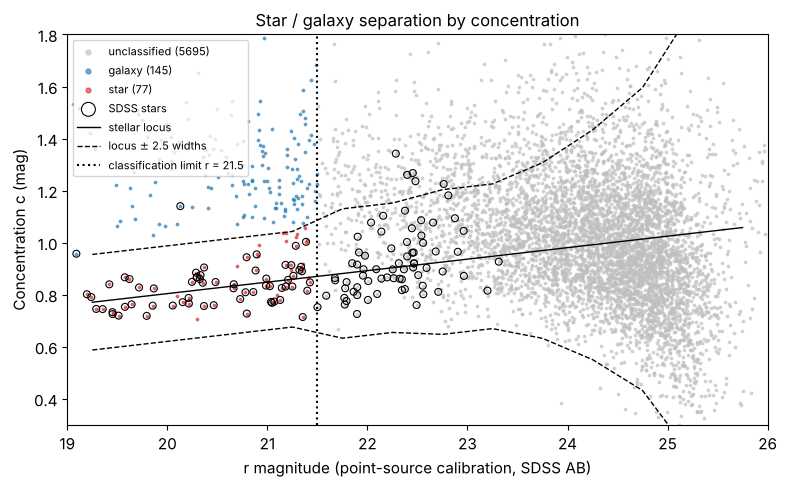

In [7]:
grid = edges_lo + BIN / 2
fig, ax = plt.subplots(figsize=(8, 5))
colours = {"unclassified": "0.75", "galaxy": "C0", "star": "C3", "artefact": "C2"}
for n in ("unclassified", "galaxy", "star"):
    sel = cls == n
    ax.scatter(mag[sel], conc[sel], s=3, color=colours[n], alpha=0.6, label=f"{n} ({sel.sum()})", rasterized=True)
ax.scatter(mag[m_idx], conc[m_idx], s=25, facecolors="none", edgecolors="k", lw=0.8, label="SDSS stars")
ax.plot(grid, locus(grid), "k", lw=1, label="stellar locus")
ax.plot(grid, locus(grid) + N_SIGMA * loc["sigma_used"], "k--", lw=1, label=f"locus $\\pm$ {N_SIGMA} widths")
ax.plot(grid, locus(grid) - N_SIGMA * loc["sigma_used"], "k--", lw=1)
ax.axvline(MAG_LIMIT, color="k", ls=":", label=f"classification limit r = {MAG_LIMIT:.1f}")
ax.set_xlim(MAG_RANGE); ax.set_ylim(0.3, 1.8)
ax.set_xlabel("r magnitude (point-source calibration, SDSS AB)"); ax.set_ylabel("Concentration c (mag)")
ax.set_title("Star / galaxy separation by concentration"); ax.legend(markerscale=2, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "05_star_galaxy_separation.png"); plt.show()

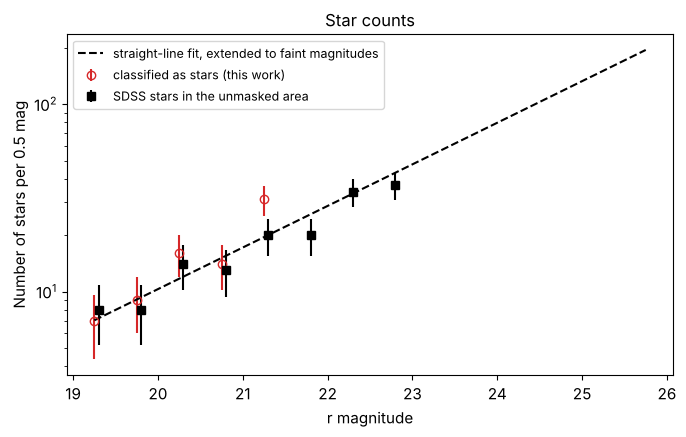

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
okc = n_class > 0; okr = n_ref > 0
ax.errorbar(centres[okc], n_class[okc], np.sqrt(n_class[okc]), fmt="o", mfc="none", color="C3", label="classified as stars (this work)")
ax.errorbar(centres[okr] + 0.05, n_ref[okr], np.sqrt(n_ref[okr]), fmt="s", color="k", label="SDSS stars in the unmasked area")
ax.plot(centres, pred, "k--", label="straight-line fit, extended to faint magnitudes")
ax.set_yscale("log"); ax.set_xlabel("r magnitude"); ax.set_ylabel("Number of stars per 0.5 mag")
ax.set_title("Star counts"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "05_star_counts.png"); plt.show()